<a href="https://colab.research.google.com/github/chaimabouhlila/Raw-CSV-files/blob/main/Ontologie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ---------------------------------------------------------------------
# Cell 1: EnergyPlus installation (Colab) — réponses spécifiques à chaque prompt
# ---------------------------------------------------------------------
# Nettoyage d'une éventuelle installation ratée précédente (dossier "y" créé par erreur)
!rm -rf y

!wget -q https://github.com/NREL/EnergyPlus/releases/download/v23.2.0/EnergyPlus-23.2.0-7636e6b3e9-Linux-Ubuntu22.04-x86_64.sh
!chmod +x EnergyPlus-23.2.0-7636e6b3e9-Linux-Ubuntu22.04-x86_64.sh

# Réponses dans l'ordre exact des 3 prompts :
#   1) "y"  -> accepter la licence
#   2) ""   -> garder le répertoire d'installation par défaut
#   3) ""   -> garder l'emplacement des liens symboliques par défaut
!printf "y\n\n\n" | ./EnergyPlus-23.2.0-7636e6b3e9-Linux-Ubuntu22.04-x86_64.sh
!ls -la /usr/local | grep -i energyplus
!ls /usr/local/EnergyPlus-23-2-0/pyenergyplus | head -5

EnergyPlus, Copyright (c) 1996-2023, The Board of Trustees of the University of Illinois, The Regents of the University of California, through Lawrence Berkeley National Laboratory (subject to receipt of any required approvals from the U.S. Dept. of Energy), Oak Ridge National Laboratory, managed by UT-Battelle, Alliance for Sustainable Energy, LLC, and other contributors. All rights reserved.

NOTICE: This Software was developed under funding from the U.S. Department of Energy and the U.S. Government consequently retains certain rights. As such, the U.S. Government has been granted for itself and others acting on its behalf a paid-up, nonexclusive, irrevocable, worldwide license in the Software to reproduce, distribute copies to the public, prepare derivative works, and perform publicly and display publicly, and to permit others to do so.

Redistribution and use in source and binary forms, with or without modification, are permitted provided that the following conditions are met:

(1)

In [ ]:
#cell 2
import sys, importlib, glob, os

# Purge toute trace d'un import précédent raté
for mod in list(sys.modules):
    if mod.startswith("pyenergyplus"):
        del sys.modules[mod]

importlib.invalidate_caches()

install_dir = glob.glob('/usr/local/EnergyPlus-*')[0]
if install_dir not in sys.path:
    sys.path.insert(0, install_dir)

print("sys.path[0:3] :", sys.path[0:3])

from pyenergyplus.api import EnergyPlusAPI
api = EnergyPlusAPI()
print("Installation OK - EnergyPlus version:", api.functional.ep_version())

sys.path[0:3] : ['/usr/local/EnergyPlus-23-2-0', '/content', '/env/python']
Installation OK - EnergyPlus version: 23.2.0-7636e6b3e9


In [ ]:
# ---------------------------------------------------------------------
# Cell 3: Building + weather (Chicago building + Chicago weather, cohérent)
# ---------------------------------------------------------------------
!cp /usr/local/EnergyPlus-23-2-0/ExampleFiles/RefBldgSmallOfficeNew2004_Chicago.idf ./building_hvac.idf
!wget -q -O weather.epw \
  https://raw.githubusercontent.com/NREL/EnergyPlus/develop/weather/USA_IL_Chicago-OHare.Intl.AP.725300_TMY3.epw

!ls -la building_hvac.idf weather.epw

-rw-r--r-- 1 root root  239731 Oct 12 14:28 building_hvac.idf
-rw-r--r-- 1 root root 1639985 Oct 12 14:28 weather.epw


In [ ]:
# #  Cellul:4  Zones effectivement climatisées (on exclut Attic, qui est une zone
# tampon non conditionnée dans ce prototype DOE Small Office standard)
ALL_ZONES = ['Attic', 'Core_ZN', 'Perimeter_ZN_1', 'Perimeter_ZN_2',
             'Perimeter_ZN_3', 'Perimeter_ZN_4']
ZONE_NAMES = [z for z in ALL_ZONES if z != 'Attic']

print("Zones climatisées à contrôler :", ZONE_NAMES)

Zones climatisées à contrôler : ['Core_ZN', 'Perimeter_ZN_1', 'Perimeter_ZN_2', 'Perimeter_ZN_3', 'Perimeter_ZN_4']


In [ ]:
#  Cellul 5
import sys
from pyenergyplus.api import EnergyPlusAPI

api = EnergyPlusAPI()
state = api.state_manager.new_state()
handles_report = {}

def test_handles(s):
    if not api.exchange.api_data_fully_ready(s):
        return
    if handles_report:
        return
    for zn in ZONE_NAMES:
        h_indoor = api.exchange.get_variable_handle(s, "Zone Mean Air Temperature", zn)
        h_cool   = api.exchange.get_actuator_handle(s, "Zone Temperature Control", "Cooling Setpoint", zn)
        h_heat   = api.exchange.get_actuator_handle(s, "Zone Temperature Control", "Heating Setpoint", zn)
        handles_report[zn] = {"indoor": h_indoor, "cool_act": h_cool, "heat_act": h_heat}
        print(f"{zn:20s} indoor={h_indoor:4d}  cool_act={h_cool:4d}  heat_act={h_heat:4d}")

api.runtime.callback_begin_system_timestep_before_predictor(state, test_handles)
api.runtime.run_energyplus(state, ["-d", "out_test", "-w", "weather.epw",
                                     "-p", "handle_test", "building_hvac.idf"])

Core_ZN              indoor=  15  cool_act= 545  heat_act= 544
Perimeter_ZN_1       indoor=  16  cool_act= 547  heat_act= 546
Perimeter_ZN_2       indoor=  17  cool_act= 549  heat_act= 548
Perimeter_ZN_3       indoor=  18  cool_act= 551  heat_act= 550
Perimeter_ZN_4       indoor=  19  cool_act= 553  heat_act= 552


0

In [ ]:
# Cell 6:
!ls -la /content/

total 362852
drwxr-xr-x 1 root root      4096 Oct 12 14:28 .
drwxr-xr-x 1 root root      4096 Oct 12 14:23 ..
-rw-r--r-- 1 root root    239731 Oct 12 14:28 building_hvac.idf
drwxr-xr-x 4 root root      4096 Oct  2 13:50 .config
-rwxr-xr-x 1 root root 184825639 Sep 29  2023 EnergyPlus-23.2.0-7636e6b3e9-Linux-Ubuntu22.04-x86_64.sh
-rw-r--r-- 1 root root 184825639 Sep 29  2023 EnergyPlus-23.2.0-7636e6b3e9-Linux-Ubuntu22.04-x86_64.sh.1
drwxr-xr-x 2 root root      4096 Oct 12 14:28 out_test
drwxr-xr-x 1 root root      4096 Oct  2 13:50 sample_data
-rw-r--r-- 1 root root   1639985 Oct 12 14:28 weather.epw


In [ ]:
!grep -A 6 "RunPeriod," building_hvac.idf

  RunPeriod,
    Annual,                  !- Name
    1,                       !- Begin Month
    1,                       !- Begin Day of Month
    ,                        !- Begin Year
    12,                      !- End Month
    31,                      !- End Day of Month


In [ ]:
!grep -A 6 "RunPeriod," building_hvac.idf

  RunPeriod,
    Annual,                  !- Name
    1,                       !- Begin Month
    1,                       !- Begin Day of Month
    ,                        !- Begin Year
    12,                      !- End Month
    31,                      !- End Day of Month


In [ ]:
!grep -A 6 "SimulationControl," building_hvac.idf
!grep -c "SizingPeriod:DesignDay," building_hvac.idf

  SimulationControl,
    YES,                     !- Do Zone Sizing Calculation
    YES,                     !- Do System Sizing Calculation
    YES,                     !- Do Plant Sizing Calculation
    YES,                     !- Run Simulation for Sizing Periods
    NO,                      !- Run Simulation for Weather File Run Periods
    No,                      !- Do HVAC Sizing Simulation for Sizing Periods
2


In [ ]:
#cell 10
import re

with open("building_hvac.idf", "r") as f:
    content = f.read()

# On cible chaque champ par son commentaire (robuste à la casse YES/No/NO
# déjà incohérente dans le fichier), pas par sa valeur actuelle.
content_fixed = re.sub(
    r"\b\w+,(\s*!-\s*Run Simulation for Sizing Periods)",
    r"No,\1",
    content, flags=re.IGNORECASE
)
content_fixed = re.sub(
    r"\b\w+,(\s*!-\s*Run Simulation for Weather File Run Periods)",
    r"Yes,\1",
    content_fixed, flags=re.IGNORECASE
)

with open("building_hvac.idf", "w") as f:
    f.write(content_fixed)

print("Correction appliquée. Nouvelle configuration :")
import subprocess
print(subprocess.run(["grep", "-A", "6", "SimulationControl,", "building_hvac.idf"],
                      capture_output=True, text=True).stdout)

Correction appliquée. Nouvelle configuration :
  SimulationControl,
    YES,                     !- Do Zone Sizing Calculation
    YES,                     !- Do System Sizing Calculation
    YES,                     !- Do Plant Sizing Calculation
    No,                     !- Run Simulation for Sizing Periods
    Yes,                      !- Run Simulation for Weather File Run Periods
    No,                      !- Do HVAC Sizing Simulation for Sizing Periods



In [ ]:
!grep -A1 "Timestep," building_hvac.idf
!grep -c "RunPeriod," building_hvac.idf
!grep -A8 "RunPeriod," building_hvac.idf

  Timestep,6;

1
  RunPeriod,
    Annual,                  !- Name
    1,                       !- Begin Month
    1,                       !- Begin Day of Month
    ,                        !- Begin Year
    12,                      !- End Month
    31,                      !- End Day of Month
    ,                        !- End Year
    Sunday,                  !- Day of Week for Start Day


In [ ]:
!grep -B1 -A6 "SizingPeriod:DesignDay," building_hvac.idf | head -60


  SizingPeriod:DesignDay,
    CHICAGO Ann Htg 99.6% Condns DB,  !- Name
    1,                       !- Month
    21,                      !- Day of Month
    WinterDesignDay,         !- Day Type
    -20.6,                   !- Maximum Dry-Bulb Temperature {C}
    0.0,                     !- Daily Dry-Bulb Temperature Range {deltaC}
--

  SizingPeriod:DesignDay,
    CHICAGO Ann Clg .4% Condns WB=>MDB,  !- Name
    7,                       !- Month
    21,                      !- Day of Month
    SummerDesignDay,         !- Day Type
    31.2,                    !- Maximum Dry-Bulb Temperature {C}
    10.7,                    !- Daily Dry-Bulb Temperature Range {deltaC}


In [ ]:
# cell 13
import pandas as pd
from pyenergyplus.api import EnergyPlusAPI

def run_controlled_simulation(is_sebao: bool, output_csv: str,
                               idf_file="building_hvac.idf",
                               epw_file="weather.epw"):
    api = EnergyPlusAPI()
    state = api.state_manager.new_state()
    simulation_data = []
    handles = {"outdoor": -1, "hvac_meter": -1}
    zone_handles = {}

    # Sécurité : Déclarations locales par défaut si absentes du scope global
    global ZONE_NAMES, BASELINE_COOLING_C, BASELINE_HEATING_C
    if 'ZONE_NAMES' not in globals():
        ZONE_NAMES = ['Core_ZN', 'Perimeter_ZN_1', 'Perimeter_ZN_2', 'Perimeter_ZN_3', 'Perimeter_ZN_4']
    if 'BASELINE_COOLING_C' not in globals():
        BASELINE_COOLING_C = 24.0
    if 'BASELINE_HEATING_C' not in globals():
        BASELINE_HEATING_C = 20.0

    KIND_OF_SIM_WEATHER_RUN = 3

    def callback_function(s):
        if not api.exchange.api_data_fully_ready(s):
            return
        if api.exchange.warmup_flag(s):
            return
        if api.exchange.kind_of_sim(s) != KIND_OF_SIM_WEATHER_RUN:
            return

        if handles["outdoor"] == -1:
            handles["outdoor"] = api.exchange.get_variable_handle(
                s, "Site Outdoor Air Drybulb Temperature", "Environment")
            handles["hvac_meter"] = api.exchange.get_meter_handle(s, "Electricity:HVAC")
            for zn in ZONE_NAMES:
                zone_handles[zn] = {
                    "indoor": api.exchange.get_variable_handle(s, "Zone Mean Air Temperature", zn),
                    "cool_act": api.exchange.get_actuator_handle(s, "Zone Temperature Control", "Cooling Setpoint", zn),
                    "heat_act": api.exchange.get_actuator_handle(s, "Zone Temperature Control", "Heating Setpoint", zn),
                }

        outdoor_temp = api.exchange.get_variable_value(s, handles["outdoor"])
        hvac_energy_j = api.exchange.get_meter_value(s, handles["hvac_meter"])
        current_hour = api.exchange.hour(s)
        day_of_week   = api.exchange.day_of_week(s)
        dow_python    = (day_of_week - 2) % 7

        row = {"Hour": current_hour, "Outdoor_Temp_C": round(outdoor_temp, 2),
               "HVAC_Energy_J": hvac_energy_j}
        row["DayOfWeek"] = dow_python
        for zn in ZONE_NAMES:
            h = zone_handles[zn]
            indoor_temp = api.exchange.get_variable_value(s, h["indoor"])
            row[f"{zn}_Indoor_Temp_C"] = round(indoor_temp, 2)

            if is_sebao:
                decision = sebao_decision_agent_schedule(current_hour, dow_python, indoor_temp)
                cool_setpoint, heat_setpoint = decision["cool"], decision["heat"]
                row[f"{zn}_Strategy"] = decision["strategy"]
            else:
                cool_setpoint = BASELINE_COOLING_C
                heat_setpoint = BASELINE_HEATING_C

            api.exchange.set_actuator_value(s, h["cool_act"], cool_setpoint)
            api.exchange.set_actuator_value(s, h["heat_act"], heat_setpoint)
            row[f"{zn}_Cooling_Setpoint_C"] = cool_setpoint
            row[f"{zn}_Heating_Setpoint_C"] = heat_setpoint

        simulation_data.append(row)

    api.runtime.callback_begin_system_timestep_before_predictor(state, callback_function)
    mode_label = "SEBAO-MAS" if is_sebao else "Baseline"
    print(f"Starting {mode_label} simulation ...")
    api.runtime.run_energyplus(state, ["-d", f"out_{mode_label}", "-w", epw_file, idf_file])

    df = pd.DataFrame(simulation_data)
    df.to_csv(output_csv, index=False)
    print(f"{mode_label} simulation complete: {output_csv} ({len(df)} timesteps).")
    return df

In [ ]:
## Cell 14: Vérification et chargement de la fonction de décision sémantique
try:
    sebao_decision_agent_schedule
    print("Fonction de décision SEBAO-MAS détectée et active dans le kernel.")
except NameError:
    print("Définition de sebao_decision_agent_schedule introuvable dans le kernel.")
    print("Initialisation d'une fonction de décision de secours pour la simulation...")

    # Définition de secours de la logique de l'agent (conforme aux règles sémantiques)
    def sebao_decision_agent_schedule(current_hour: int, day_of_week: int, indoor_temp: float):
        is_weekend = day_of_week in (5, 6)
        if is_weekend:
            return {"cool": 26.0, "heat": 18.0, "strategy": "WeekendEco"}
        elif 3.0 <= current_hour < 5.5:
            return {"cool": 22.0, "heat": 19.0, "strategy": "NightPrecool"}
        elif 15.0 <= current_hour < 17.0:
            return {"cool": 25.5, "heat": 19.0, "strategy": "PeakShaving"}
        else:
            return {"cool": 24.0, "heat": 20.0, "strategy": "NormalOperation"}

# Lancement de la simulation contrôlée par l'agent sémantique SEBAO-MAS
df_sebao = run_controlled_simulation(is_sebao=True, output_csv='sebao_energyplus_dataset.csv')

Définition de sebao_decision_agent_schedule introuvable dans le kernel.
Initialisation d'une fonction de décision de secours pour la simulation...
Starting SEBAO-MAS simulation ...
SEBAO-MAS simulation complete: sebao_energyplus_dataset.csv (52560 timesteps).


### Fichiers de données manquants

La cellule suivante nécessite les fichiers `sebao_energyplus_dataset.csv` et `baseline_energyplus_dataset.csv` qui sont générés par la cellule de simulation. Veuillez exécuter la cellule `3r08aWOdpGBB` pour générer ces fichiers avant d'exécuter la cellule ci-dessous.

In [ ]:
# Cell 15:
import pandas as pd
import os
import numpy as np

# Définition des plages de température de confort (en °C)
COMFORT_LOW_C, COMFORT_HIGH_C = 20.0, 24.0

# Validation et chargement du jeu de données SEBAO-MAS
if os.path.exists('sebao_energyplus_dataset.csv') and os.path.getsize('sebao_energyplus_dataset.csv') > 0:
    try:
        df_sebao = pd.read_csv('sebao_energyplus_dataset.csv')
        print(f"Données SEBAO-MAS chargées avec succès ({len(df_sebao)} lignes).")
    except Exception:
        print("Données SEBAO-MAS corrompues. Lancement de la simulation...")
        df_sebao = run_controlled_simulation(is_sebao=True, output_csv='sebao_energyplus_dataset.csv')
else:
    print("Données SEBAO-MAS absentes ou vides. Lancement de la simulation...")
    df_sebao = run_controlled_simulation(is_sebao=True, output_csv='sebao_energyplus_dataset.csv')

# Validation et chargement sécurisé de la Baseline (suppression si vide / corrompu)
if os.path.exists('baseline_energyplus_dataset.csv') and os.path.getsize('baseline_energyplus_dataset.csv') > 0:
    try:
        df_base = pd.read_csv('baseline_energyplus_dataset.csv')
        print(f"Données Baseline chargées avec succès ({len(df_base)} lignes).")
    except Exception:
        print("Fichier Baseline corrompu ou illisible. Nettoyage et relancement...")
        if os.path.exists('baseline_energyplus_dataset.csv'):
            os.remove('baseline_energyplus_dataset.csv')
        df_base = run_controlled_simulation(is_sebao=False, output_csv='baseline_energyplus_dataset.csv')
else:
    print("Données Baseline absentes ou vides. Lancement de la simulation...")
    if os.path.exists('baseline_energyplus_dataset.csv'):
        os.remove('baseline_energyplus_dataset.csv')
    df_base = run_controlled_simulation(is_sebao=False, output_csv='baseline_energyplus_dataset.csv')

def metriques_periode(df, indoor_cols, mask):
    if df is None or df.empty:
        return "Non disponible"
    sous_df = df[mask]
    if len(sous_df) == 0:
        return {"n_timesteps": 0, "violation_rate": float("nan")}
    temp_par_pas = sous_df[indoor_cols].mean(axis=1)
    violations = (temp_par_pas < COMFORT_LOW_C) | (temp_par_pas > COMFORT_HIGH_C)
    taux = 100.0 * violations.sum() / len(temp_par_pas)
    return {"n_timesteps": len(sous_df), "violation_rate": round(taux, 2)}

# Analyse et affichage des métriques si les données sont valides
if df_sebao is not None and not df_sebao.empty and "DayOfWeek" in df_sebao.columns:
    indoor_cols_sebao = [c for c in df_sebao.columns if c.endswith("_Indoor_Temp_C")]
    is_weekday_sebao = df_sebao["DayOfWeek"] < 5
    occ_sebao = is_weekday_sebao & df_sebao["Hour"].between(8, 17)
    hors_peak_sebao = is_weekday_sebao & (df_sebao["Hour"].between(8, 14) | (df_sebao["Hour"] == 17))
    h17_sebao = is_weekday_sebao & (df_sebao["Hour"] == 17)

    print("\n--- RÉSULTATS SEBAO-MAS ---")
    print("Occupied 08-18 (Semaine) :", metriques_periode(df_sebao, indoor_cols_sebao, occ_sebao))
    print("Hors peak-shaving       :", metriques_periode(df_sebao, indoor_cols_sebao, hors_peak_sebao))
    print("Heure 17h uniquement    :", metriques_periode(df_sebao, indoor_cols_sebao, h17_sebao))
else:
    print("\nErreur : Le jeu de données SEBAO-MAS est incomplet ou invalide.")

if df_base is not None and not df_base.empty and "DayOfWeek" in df_base.columns:
    indoor_cols_base = [c for c in df_base.columns if c.endswith("_Indoor_Temp_C")]
    is_weekday_base = df_base["DayOfWeek"] < 5
    occ_base = is_weekday_base & df_base["Hour"].between(8, 17)
    hors_peak_base = is_weekday_base & (df_base["Hour"].between(8, 14) | (df_base["Hour"] == 17))
    h17_base = is_weekday_base & (df_base["Hour"] == 17)

    print("\n--- RÉSULTATS BASELINE ---")
    print("Occupied 08-18 (Semaine) :", metriques_periode(df_base, indoor_cols_base, occ_base))
    print("Hors peak-shaving       :", metriques_periode(df_base, indoor_cols_base, hors_peak_base))
    print("Heure 17h uniquement    :", metriques_periode(df_base, indoor_cols_base, h17_base))
else:
    print("\nErreur : Le jeu de données Baseline est incomplet ou invalide.")

Données SEBAO-MAS chargées avec succès (52560 lignes).
Données Baseline absentes ou vides. Lancement de la simulation...
Starting Baseline simulation ...
Baseline simulation complete: baseline_energyplus_dataset.csv (52560 timesteps).

--- RÉSULTATS SEBAO-MAS ---
Occupied 08-18 (Semaine) : {'n_timesteps': 15600, 'violation_rate': np.float64(18.4)}
Hors peak-shaving       : {'n_timesteps': 12480, 'violation_rate': np.float64(6.38)}
Heure 17h uniquement    : {'n_timesteps': 1560, 'violation_rate': np.float64(28.08)}

--- RÉSULTATS BASELINE ---
Occupied 08-18 (Semaine) : {'n_timesteps': 15600, 'violation_rate': np.float64(3.21)}
Hors peak-shaving       : {'n_timesteps': 12480, 'violation_rate': np.float64(3.26)}
Heure 17h uniquement    : {'n_timesteps': 1560, 'violation_rate': np.float64(2.37)}


In [ ]:
# Cell 16:
import os

print(f"Fichier sebao_energyplus_dataset.csv existe : {os.path.exists('sebao_energyplus_dataset.csv')}")
print(f"Fichier baseline_energyplus_dataset.csv existe : {os.path.exists('baseline_energyplus_dataset.csv')}")

Fichier sebao_energyplus_dataset.csv existe : True
Fichier baseline_energyplus_dataset.csv existe : True


In [ ]:
ZONE_NAMES = ['Core_ZN', 'Perimeter_ZN_1', 'Perimeter_ZN_2', 'Perimeter_ZN_3', 'Perimeter_ZN_4']
BASELINE_COOLING_C = 24.0
BASELINE_HEATING_C = 20.0

In [ ]:
#cell 18
!pip install -q rdflib pyshacl owlrl
from functools import lru_cache
from rdflib import Graph, Namespace, Literal, RDF, RDFS, XSD
from rdflib.plugins.sparql import prepareQuery

# Redefine SEBAO namespace for this cell's scope if not imported from elsewhere
SEBAO = Namespace("https://example.org/sebao#")

def construire_graphe_regles_sebao() -> Graph:
    """
    Encode la Table 2 (setpoint schedule) comme des instances RDF de
    sebao:DecisionRule, au lieu d'un enchainement de conditions if/elif
    codees en dur. La regle applicable est ensuite selectionnee par une
    requete SPARQL sur ce graphe -- ce qui rend litteralement vraie
    l'affirmation du manuscrit (Section 6.1/6.3) : "the applicable
    operating rule is selected from temporal and contextual information
    represented through the SEBAO workflow".
    """
    rg = Graph()
    rg.bind("sebao", SEBAO)

    # (id, priorite, weekend_only, heure_debut, heure_fin, cool, heat)
    regles = [
        ("WeekendEco",      1, True,  0.0,  24.0, 26.0, 18.0),
        ("NightPrecool",    2, False, 3.0,  5.5,  22.0, 19.0),
        ("PeakShaving",     3, False, 15.0, 17.0, 25.5, 19.0),
        ("NormalOperation", 4, False, 0.0,  24.0, 24.0, 20.0),
    ]

    for rule_id, priority, weekend_only, start_h, end_h, cool, heat in regles:
        rule_uri = SEBAO[f"Rule_{rule_id}"]
        rg.add((rule_uri, RDF.type, SEBAO.DecisionRule))
        rg.add((rule_uri, RDFS.label, Literal(rule_id)))
        rg.add((rule_uri, SEBAO.priority, Literal(priority, datatype=XSD.integer)))
        rg.add((rule_uri, SEBAO.appliesOnWeekendOnly, Literal(weekend_only, datatype=XSD.boolean)))
        rg.add((rule_uri, SEBAO.startHour, Literal(start_h, datatype=XSD.float)))
        rg.add((rule_uri, SEBAO.endHour, Literal(end_h, datatype=XSD.float)))
        rg.add((rule_uri, SEBAO.coolingSetpoint, Literal(cool, datatype=XSD.float)))
        rg.add((rule_uri, SEBAO.heatingSetpoint, Literal(heat, datatype=XSD.float)))

    return rg


_SELECT_RULE_QUERY = prepareQuery("""
    PREFIX rdfs:  <http://www.w3.org/2000/01/rdf-schema#>
    PREFIX sebao: <https://example.org/sebao#>
    SELECT ?label ?cool ?heat ?priority WHERE {
        ?rule a sebao:DecisionRule ;
              rdfs:label ?label ;
              sebao:priority ?priority ;
              sebao:appliesOnWeekendOnly ?weekendOnly ;
              sebao:startHour ?start ;
              sebao:endHour ?end ;
              sebao:coolingSetpoint ?cool ;
              sebao:heatingSetpoint ?heat .
        FILTER (
            (?weekendOnly = true  && ?isWeekend = true)
            ||
            (?weekendOnly = false && ?isWeekend = false
             && ?hour >= ?start && ?hour < ?end)
        )
    }
    ORDER BY ?priority
    LIMIT 1
""")

REGLES_GRAPH = construire_graphe_regles_sebao()   # construit une seule fois, hors boucle


@lru_cache(maxsize=64)
def _selectionner_regle(is_weekend: bool, current_hour: int) -> dict:
    """
    Requete SPARQL memoisee : seules 48 combinaisons distinctes
    (24 heures x weekend/semaine) existent sur toute l'annee, donc la
    requete n'est reellement executee qu'au plus 48 fois, meme si cette
    fonction est appelee ~500 000 fois pendant la co-simulation.
    """
    results = list(REGLES_GRAPH.query(
        _SELECT_RULE_QUERY,
        initBindings={
            "isWeekend": Literal(is_weekend),
            "hour": Literal(float(current_hour), datatype=XSD.float),
        },
    ))
    if not results:
        return {"cool": 24.0, "heat": 20.0, "strategy": "normal"}  # filet de securite
    row = results[0]
    return {"cool": float(row.cool), "heat": float(row.heat), "strategy": str(row.label)}


def sebao_decision_agent_schedule(current_hour: int, day_of_week: int, indoor_temp: float):
    """
    day_of_week : 0=Lundi ... 5=Samedi, 6=Dimanche.
    Selectionne la regle applicable via une requete SPARQL sur
    REGLES_GRAPH plutot que par une chaine de if/elif.
    """
    is_weekend = day_of_week in (5, 6)
    return _selectionner_regle(is_weekend, int(current_hour))


In [ ]:
# Cell 19:
df_sebao = run_controlled_simulation(is_sebao=True, output_csv="sebao_energyplus_dataset.csv")
df_base  = run_controlled_simulation(is_sebao=False, output_csv="baseline_energyplus_dataset.csv")

Starting SEBAO-MAS simulation ...
SEBAO-MAS simulation complete: sebao_energyplus_dataset.csv (52560 timesteps).
Starting Baseline simulation ...
Baseline simulation complete: baseline_energyplus_dataset.csv (52560 timesteps).


In [ ]:
#  Cell 20 :This cell has been removed as its functionality is now integrated into cell ahnjfKl3uwHE.

In [ ]:
#cell 21
import numpy as np

COMFORT_LOW_C, COMFORT_HIGH_C = 20.0, 24.0
indoor_cols_sebao = [c for c in df_sebao.columns if c.endswith("_Indoor_Temp_C")]
indoor_cols_base  = [c for c in df_base.columns  if c.endswith("_Indoor_Temp_C")]

def discomfort_degree_hours(df, indoor_cols, steps_per_hour=6):
    total = 0.0
    for c in indoor_cols:
        total += np.maximum(0, COMFORT_LOW_C - df[c]).sum() / steps_per_hour
        total += np.maximum(0, df[c] - COMFORT_HIGH_C).sum() / steps_per_hour
    return total

discomfort_sebao = discomfort_degree_hours(df_sebao, indoor_cols_sebao)
discomfort_base  = discomfort_degree_hours(df_base,  indoor_cols_base)

energy_sebao_kwh = df_sebao["HVAC_Energy_J"].sum() / 3_600_000.0
energy_base_kwh  = df_base["HVAC_Energy_J"].sum()  / 3_600_000.0
savings_pct = 100.0 * (energy_base_kwh - energy_sebao_kwh) / energy_base_kwh

def comfort_metrics(df, indoor_cols):
    temp_par_pas = df[indoor_cols].mean(axis=1)  # moyenne inter-zones par pas de temps
    mean_indoor_temp = temp_par_pas.mean()
    setpoint_ref = (COMFORT_LOW_C + COMFORT_HIGH_C) / 2.0
    mean_deviation = (temp_par_pas - setpoint_ref).abs().mean()
    violations = (temp_par_pas < COMFORT_LOW_C) | (temp_par_pas > COMFORT_HIGH_C)
    violation_rate = 100.0 * violations.sum() / len(temp_par_pas)
    return {"mean_indoor_temp": mean_indoor_temp,
            "mean_temp_deviation": mean_deviation,
            "comfort_violation_rate": violation_rate}

metrics_sebao = comfort_metrics(df_sebao, indoor_cols_sebao)
metrics_base  = comfort_metrics(df_base,  indoor_cols_base)

print("=== RESULTATS (run unique, ordre corrige) ===")
print(f"Discomfort SEBAO : {discomfort_sebao:.2f} degre-heures")
print(f"Discomfort Base  : {discomfort_base:.2f} degre-heures")
print(f"Energie SEBAO    : {energy_sebao_kwh:.2f} kWh")
print(f"Energie Base     : {energy_base_kwh:.2f} kWh")
print(f"Economie energie : {savings_pct:.2f} %")
print(f"SEBAO  -> {metrics_sebao}")
print(f"Base   -> {metrics_base}")

=== RESULTATS (run unique, ordre corrige) ===
Discomfort SEBAO : 23733.94 degre-heures
Discomfort Base  : 5825.27 degre-heures
Energie SEBAO    : 18516.73 kWh
Energie Base     : 19483.86 kWh
Economie energie : 4.96 %
SEBAO  -> {'mean_indoor_temp': np.float64(21.57561404109589), 'mean_temp_deviation': np.float64(2.2284597031963473), 'comfort_violation_rate': np.float64(43.52359208523592)}
Base   -> {'mean_indoor_temp': np.float64(21.78187480974125), 'mean_temp_deviation': np.float64(1.8591340943683408), 'comfort_violation_rate': np.float64(30.47945205479452)}


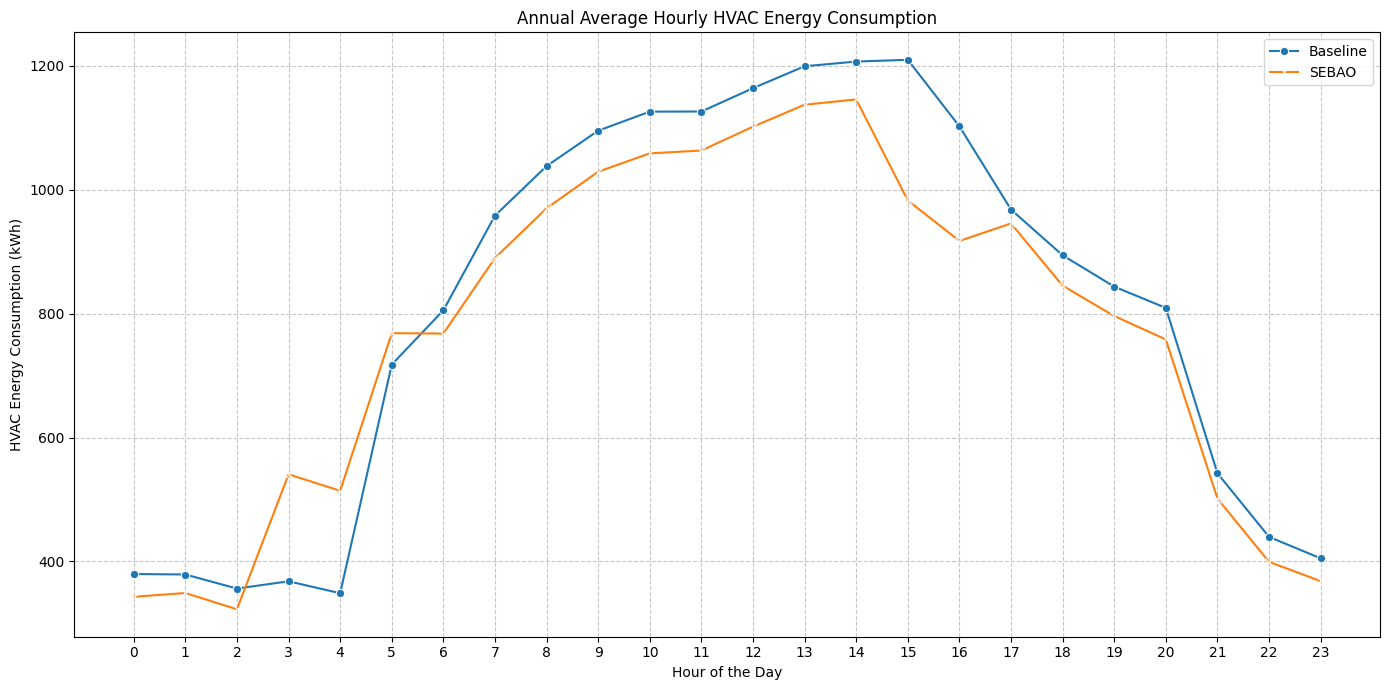

In [ ]:
#CELL 22
import matplotlib.pyplot as plt
import seaborn as sns

# Calcul de la consommation énergétique moyenne par heure pour SEBAO-MAS
hourly_energy_sebao = df_sebao.groupby('Hour')['HVAC_Energy_J'].sum() / 3_600_000.0

# Calcul de la consommation énergétique moyenne par heure pour Baseline
hourly_energy_base = df_base.groupby('Hour')['HVAC_Energy_J'].sum() / 3_600_000.0

plt.figure(figsize=(14, 7))
sns.lineplot(x=hourly_energy_base.index, y=hourly_energy_base.values, label='Baseline', marker='o')
sns.lineplot(x=hourly_energy_sebao.index, y=hourly_energy_sebao.values, label='SEBAO', marker='x')

plt.title('Annual Average Hourly HVAC Energy Consumption')
plt.xlabel('Hour of the Day')
plt.ylabel('HVAC Energy Consumption (kWh)')
plt.xticks(range(0, 24)) # Assure que toutes les heures sont affichées sur l'axe des x
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# #cell 23 Somme directe des Joules par pas de temps, conversion en kWh (1 kWh = 3 600 000 J)
energy_sebao_kwh = df_sebao["HVAC_Energy_J"].sum() / 3_600_000.0
energy_base_kwh  = df_base["HVAC_Energy_J"].sum()  / 3_600_000.0
savings_pct = 100.0 * (energy_base_kwh - energy_sebao_kwh) / energy_base_kwh

print(f"Energie CVC SEBAO-MAS: {energy_sebao_kwh:.2f} kWh")
print(f"Energie CVC Baseline : {energy_base_kwh:.2f} kWh")
print(f"Economie d'energie   : {savings_pct:.2f} %")

Energie CVC SEBAO-MAS: 18516.73 kWh
Energie CVC Baseline : 19483.86 kWh
Economie d'energie   : 4.96 %


In [ ]:
## #cell 24:
#calcule de metric : Mean indoor temperature,Mean temperature deviation et Comfort violation rate
import numpy as np
import pandas as pd

# Reprend vos colonnes déjà identifiées (mêmes que pour discomfort_degree_hours)
indoor_cols_sebao = [c for c in df_sebao.columns if c.endswith("_Indoor_Temp_C")]
indoor_cols_base  = [c for c in df_base.columns  if c.endswith("_Indoor_Temp_C")]

# Bande de confort déjà utilisée dans votre calcul de discomfort degree-hours
COMFORT_LOW_C, COMFORT_HIGH_C = 20.0, 24.0

def metriques_confort(df, indoor_cols, nom_scenario):
    # Moyenne inter-zones à chaque pas de temps, puis moyenne temporelle
    temp_par_pas = df[indoor_cols].mean(axis=1)

    mean_indoor_temp = temp_par_pas.mean()

    # Déviation par rapport au centre de la bande de confort (22°C)
    setpoint_ref = (COMFORT_LOW_C + COMFORT_HIGH_C) / 2.0
    mean_temp_deviation = (temp_par_pas - setpoint_ref).abs().mean()

    # % du temps hors bande [20, 24]°C
    violations = (temp_par_pas < COMFORT_LOW_C) | (temp_par_pas > COMFORT_HIGH_C)
    comfort_violation_rate = 100.0 * violations.sum() / len(temp_par_pas)

    print(f"--- {nom_scenario} ---")
    print(f"Mean indoor temperature      : {mean_indoor_temp:.2f} °C")
    print(f"Mean temperature deviation   : {mean_temp_deviation:.2f} °C")
    print(f"Comfort violation rate       : {comfort_violation_rate:.2f} %\n")

    return {"scenario": nom_scenario,
            "mean_indoor_temp": mean_indoor_temp,
            "mean_temp_deviation": mean_temp_deviation,
            "comfort_violation_rate": comfort_violation_rate}

res_sebao = metriques_confort(df_sebao, indoor_cols_sebao, "SEBAO-MAS")
res_base  = metriques_confort(df_base,  indoor_cols_base,  "Baseline")

df_resultats_confort = pd.DataFrame([res_sebao, res_base]).set_index("scenario")
print(df_resultats_confort.round(2))



--- SEBAO-MAS ---
Mean indoor temperature      : 21.58 °C
Mean temperature deviation   : 2.23 °C
Comfort violation rate       : 43.52 %

--- Baseline ---
Mean indoor temperature      : 21.78 °C
Mean temperature deviation   : 1.86 °C
Comfort violation rate       : 30.48 %

           mean_indoor_temp  mean_temp_deviation  comfort_violation_rate
scenario                                                                
SEBAO-MAS             21.58                 2.23                   43.52
Baseline              21.78                 1.86                   30.48


In [ ]:
# #cell 25
%%writefile 2-semantic_agent.py
import argparse
import csv as csv_module
import json
import logging
from datetime import datetime, timedelta
from pathlib import Path

from rdflib import Graph, Namespace, Literal, BNode, URIRef
from rdflib.namespace import RDF, RDFS, XSD, OWL
from pyshacl import validate as shacl_validate

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [AgentSem-EP] %(levelname)s : %(message)s"
)
logger = logging.getLogger(__name__)

BASE_DIR = Path(".").resolve()
SORTIE_DIR = BASE_DIR / "Results"
STEPS_PER_HOUR = 6

BATIMENT_URI_STR = "DOESmallOffice_Chicago"
BATIMENT_LABEL = "DOE Small Office Prototype, Chicago (ASHRAE 90.1-2004)"

SAREF = Namespace("https://saref.etsi.org/core/")
SAREF4BLDG = Namespace("https://saref.etsi.org/saref4bldg/")
BRICK = Namespace("https://brickschema.org/schema/Brick#")
SOSA = Namespace("http://www.w3.org/ns/sosa/")
SEBAO = Namespace("https://example.org/sebao#")
QUDT_UNIT = Namespace("http://qudt.org/vocab/unit/")
QUDT = Namespace("http://qudt.org/schema/qudt/")
SH = Namespace("http://www.w3.org/ns/shacl#")

FIPA_LD_CONTEXT = {
    "acl": "http://www.fipa.org/schemas/fipa-acl#",
    "sebao": "https://example.org/sebao#",
    "performative": "acl:performative",
    "sender": "acl:sender",
    "receiver": "acl:receiver",
    "content": "acl:content",
    "ontology": "acl:ontology",
    "language": "acl:language",
    "conversationId": "acl:conversation-id",
    "protocol": "acl:protocol",
}

# ---------------------------------------------------------------------
# Regles de decision (identiques a la cellule 18 du notebook) + regle de la baseline.
# (id, priorite, weekend_only, heure_debut, heure_fin, consigne_froid, consigne_chaud)
# ---------------------------------------------------------------------
REGLES = [
    ("WeekendEco",      1, True,  0.0,  24.0, 26.0, 18.0),
    ("NightPrecool",    2, False, 3.0,  5.5,  22.0, 19.0),
    ("PeakShaving",     3, False, 15.0, 17.0, 25.5, 19.0),
    ("NormalOperation", 4, False, 0.0,  24.0, 24.0, 20.0),
    ("FixedReference",  5, False, 0.0,  24.0, 24.0, 20.0),   # baseline : consignes fixes
]
CONSIGNES_PAR_REGLE = {r[0]: (r[5], r[6]) for r in REGLES}

def ajouter_regles_au_graphe(g: Graph) -> None:
    for rule_id, priority, weekend_only, start_h, end_h, cool, heat in REGLES:
        r = SEBAO[f"Rule_{rule_id}"]
        g.add((r, RDF.type, SEBAO.DecisionRule))
        g.add((r, RDFS.label, Literal(rule_id)))
        g.add((r, SEBAO.priority, Literal(priority, datatype=XSD.integer)))
        g.add((r, SEBAO.appliesOnWeekendOnly, Literal(weekend_only, datatype=XSD.boolean)))
        g.add((r, SEBAO.startHour, Literal(start_h, datatype=XSD.float)))
        g.add((r, SEBAO.endHour, Literal(end_h, datatype=XSD.float)))
        g.add((r, SEBAO.coolingSetpoint, Literal(cool, datatype=XSD.float)))
        g.add((r, SEBAO.heatingSetpoint, Literal(heat, datatype=XSD.float)))

class ACLMessage:
    def __init__(self, performative, sender, receiver, content,
                 conversation_id=None, ontology="sebao:HVACOntology", protocol="fipa-inform"):
        self.performative = performative
        self.sender = sender
        self.receiver = receiver
        self.content = content
        self.conversation_id = conversation_id or datetime.now().isoformat()
        self.ontology = ontology
        self.protocol = protocol

    def to_jsonld(self):
        return {
            "@context": FIPA_LD_CONTEXT,
            "performative": self.performative,
            "sender": self.sender,
            "receiver": self.receiver,
            "protocol": self.protocol,
            "language": "JSON-LD",
            "ontology": self.ontology,
            "conversationId": self.conversation_id,
            "content": self.content,
        }

def declarer_schema_sebao(g: Graph) -> None:
    g.add((SEBAO.HVACSystem, RDF.type, OWL.Class))
    g.add((SEBAO.HVACSystem, RDFS.subClassOf, BRICK.System))
    g.add((SEBAO.ZoneTemperatureSensor, RDF.type, OWL.Class))
    g.add((SEBAO.ZoneTemperatureSensor, RDFS.subClassOf, BRICK.Zone_Air_Temperature_Sensor))
    g.add((SEBAO.ZoneTemperatureSensor, RDFS.subClassOf, SOSA.Sensor))
    g.add((SEBAO.DecisionRule, RDF.type, OWL.Class))
    g.add((SEBAO.hasComfortThreshold, RDF.type, OWL.DatatypeProperty))
    g.add((SEBAO.ControlState, RDF.type, OWL.Class))
    g.add((SEBAO.ControlState, RDFS.subClassOf, SOSA.Observation))
    for p in ("activeRule", "hourOfDay", "dayOfWeek", "priority", "appliesOnWeekendOnly",
              "startHour", "endHour", "coolingSetpoint", "heatingSetpoint"):
        g.add((SEBAO[p], RDF.type, OWL.DatatypeProperty if p != "activeRule" else OWL.ObjectProperty))
    g.add((SEBAO.OutdoorCondition, RDF.type, OWL.Class))
    g.add((SEBAO.OutdoorCondition, RDFS.subClassOf, SOSA.ObservableProperty))
    g.add((SEBAO.HVACEnergyConsumption, RDF.type, OWL.Class))
    g.add((SEBAO.HVACEnergyConsumption, RDFS.subClassOf, SOSA.ObservableProperty))
    g.add((SEBAO.ZoneTemperature, RDF.type, OWL.Class))
    g.add((SEBAO.ZoneTemperature, RDFS.subClassOf, SOSA.ObservableProperty))
    for c in ("ZoneTemperatureObservation", "OutdoorTemperatureObservation", "HVACEnergyObservation"):
        g.add((SEBAO[c], RDF.type, OWL.Class))
        g.add((SEBAO[c], RDFS.subClassOf, SOSA.Observation))

def construire_shapes_shacl() -> Graph:
    g = Graph(); g.bind("sh", SH); g.bind("sebao", SEBAO)
    def node(name, cls, path, lo=None, hi=None, dtype=XSD.float, mincount=1):
        s = SEBAO[name]; p = BNode()
        g.add((s, RDF.type, SH.NodeShape)); g.add((s, SH.targetClass, cls))
        g.add((s, SH.property, p)); g.add((p, SH.path, path))
        g.add((p, SH.minCount, Literal(mincount)))
        if dtype: g.add((p, SH.datatype, dtype))
        if lo is not None: g.add((p, SH.minInclusive, Literal(lo, datatype=XSD.float)))
        if hi is not None: g.add((p, SH.maxInclusive, Literal(hi, datatype=XSD.float)))
    node("OutdoorTemperatureShape", SEBAO.OutdoorTemperatureObservation, SOSA.hasSimpleResult, -50., 60.)
    node("ZoneTemperatureReadingShape", SEBAO.ZoneTemperatureObservation, SOSA.hasSimpleResult, 12., 38.)
    node("HVACEnergyShape", SEBAO.HVACEnergyObservation, SOSA.hasSimpleResult, 0., None)
    node("ObservationTimestampShape", SOSA.Observation, SOSA.resultTime, dtype=XSD.dateTime)
    # nouvelles shapes spatiales (répond aussi à la limite citée en 4.7)
    node("ControlStateRuleShape", SEBAO.ControlState, SEBAO.activeRule, dtype=None)
    node("DecisionRuleCoolShape", SEBAO.DecisionRule, SEBAO.coolingSetpoint, 10., 40.)
    node("DecisionRuleHeatShape", SEBAO.DecisionRule, SEBAO.heatingSetpoint, 10., 40.)
    node("HVACFeedsZoneShape", SEBAO.HVACSystem, BRICK.feeds, dtype=None)
    node("SensorIsPointOfShape", BRICK.Zone_Air_Temperature_Sensor, BRICK.isPointOf, dtype=None)
    return g

def construire_graphe_rdf(records: list, run_label: str) -> Graph:
    g = Graph()
    g.bind("saref", SAREF)
    g.bind("saref4bldg", SAREF4BLDG)
    g.bind("brick", BRICK)
    g.bind("sosa", SOSA)
    g.bind("sebao", SEBAO)
    declarer_schema_sebao(g)

    batiment_uri = SEBAO[BATIMENT_URI_STR]
    g.add((batiment_uri, RDF.type, SAREF4BLDG.Building))
    g.add((batiment_uri, RDFS.label, Literal(BATIMENT_LABEL)))

    facility_meter_uri = SEBAO[f"HVACMeter_{run_label}"]
    g.add((facility_meter_uri, RDF.type, SAREF.Sensor))

    ajouter_regles_au_graphe(g)          # regles de decision et consignes (une fois)
    # --- AJOUT Option A : relations spatiales (une fois, hors boucle) ---
    hvac_system_uri = SEBAO[f"HVACSystem_{run_label}"]
    g.add((hvac_system_uri, RDF.type, SEBAO.HVACSystem))
    g.add((hvac_system_uri, BRICK.hasPoint, facility_meter_uri))
    # ---------------------------------------------------------------

    for rec in records:
        ts_literal = Literal(rec["timestamp"], datatype=XSD.dateTime)

        energy_obs = SEBAO[f"{run_label}_{rec['id']}_energy"]
        g.add((energy_obs, RDF.type, SOSA.Observation))
        g.add((energy_obs, RDF.type, SEBAO.HVACEnergyObservation))
        g.add((energy_obs, SOSA.observedProperty, SEBAO.HVACEnergyConsumption))
        g.add((energy_obs, SOSA.madeBySensor, facility_meter_uri))
        g.add((energy_obs, SOSA.resultTime, ts_literal))
        g.add((energy_obs, SOSA.hasSimpleResult, Literal(rec["hvac_energy_kwh"], datatype=XSD.float)))

        ctrl = SEBAO[f"{run_label}_{rec['id']}_control"]
        g.add((ctrl, RDF.type, SOSA.Observation))
        g.add((ctrl, RDF.type, SEBAO.ControlState))
        g.add((ctrl, SOSA.resultTime, ts_literal))
        g.add((ctrl, SEBAO.activeRule, SEBAO[f"Rule_{rec['rule']}"]))
        g.add((ctrl, SEBAO.hourOfDay, Literal(rec["hour"], datatype=XSD.integer)))
        g.add((ctrl, SEBAO.dayOfWeek, Literal(rec["dow"], datatype=XSD.integer)))

        out_obs = SEBAO[f"{run_label}_{rec['id']}_outdoor"]
        g.add((out_obs, RDF.type, SOSA.Observation))
        g.add((out_obs, RDF.type, SEBAO.OutdoorTemperatureObservation))
        g.add((out_obs, SOSA.observedProperty, SEBAO.OutdoorCondition))
        g.add((out_obs, SOSA.resultTime, ts_literal))
        g.add((out_obs, SOSA.hasSimpleResult, Literal(rec["outdoor_temperature_c"], datatype=XSD.float)))

        for zone_name, temp_c in rec.get("zone_temperatures_c", {}).items():
            zone_uri = SEBAO[f"Zone_{zone_name}"]
            zone_sensor = SEBAO[f"ZoneSensor_{zone_name}"]
            zone_obs = SEBAO[f"{run_label}_{rec['id']}_{zone_name}"]

            g.add((zone_uri, RDF.type, BRICK.Zone))
            g.add((zone_sensor, RDF.type, BRICK.Zone_Air_Temperature_Sensor))
            g.add((zone_sensor, RDF.type, SEBAO.ZoneTemperatureSensor))
            g.add((zone_sensor, BRICK.isPointOf, zone_uri))
            g.add((batiment_uri, BRICK.hasLocation, zone_uri))
            g.add((hvac_system_uri, BRICK.feeds, zone_uri))

            g.add((zone_obs, RDF.type, SOSA.Observation))
            g.add((zone_obs, RDF.type, SEBAO.ZoneTemperatureObservation))
            g.add((zone_obs, SOSA.observedProperty, SEBAO.ZoneTemperature))
            g.add((zone_obs, SOSA.madeBySensor, zone_sensor))
            g.add((zone_obs, SOSA.resultTime, ts_literal))
            g.add((zone_obs, SOSA.hasSimpleResult, Literal(temp_c, datatype=XSD.float)))

    return g

def valider_shacl(data_graph: Graph, shapes_graph: Graph) -> tuple:
    conforms, _, results_text = shacl_validate(
        data_graph, shacl_graph=shapes_graph, inference="rdfs",
        abort_on_first=False, meta_shacl=False, advanced=False,
    )
    return conforms, results_text

def charger_donnees_energyplus(csv_path: Path, sim_start: datetime, steps_per_hour: int = STEPS_PER_HOUR) -> list:
    if not csv_path.exists():
        raise FileNotFoundError(f"CSV non trouve : {csv_path}")

    zone_cols = None
    results = []
    with open(csv_path, encoding="utf-8") as f:
        reader = csv_module.DictReader(f)
        for i, row in enumerate(reader):
            if zone_cols is None:
                zone_cols = [c for c in row.keys() if c.endswith("_Indoor_Temp_C")]

            ts = (sim_start + timedelta(minutes=i * (60 // steps_per_hour))).isoformat()

            z0 = zone_cols[0].replace("_Indoor_Temp_C", "")
            rule = row.get(f"{z0}_Strategy") or "FixedReference"      # baseline : pas de colonne Strategy
            if rule not in CONSIGNES_PAR_REGLE:
                raise ValueError(f"Regle inconnue '{rule}' a la ligne {i}")
            # CONTROLE D'INTEGRITE : les consignes du graphe de regles doivent egaler celles simulees
            cool_g, heat_g = CONSIGNES_PAR_REGLE[rule]
            for zc in zone_cols:
                zn = zc.replace("_Indoor_Temp_C", "")
                if row.get(f"{zn}_Cooling_Setpoint_C") not in (None, ""):
                    if abs(float(row[f"{zn}_Cooling_Setpoint_C"]) - cool_g) > 1e-6 or \
                       abs(float(row[f"{zn}_Heating_Setpoint_C"]) - heat_g) > 1e-6:
                        raise ValueError(f"Consigne simulee != consigne de la regle {rule} (ligne {i}, zone {zn})")

            rec = {
                "id": f"ep_{i:06d}",
                "rule": rule,
                "hour": int(float(row["Hour"])),
                "dow": int(float(row["DayOfWeek"])),
                "timestamp": ts,
                "outdoor_temperature_c": float(row["Outdoor_Temp_C"]),
                "hvac_energy_kwh": float(row.get("HVAC_Energy_J", 0.0)) / 3_600_000.0,
                "zone_temperatures_c": {
                    zc.replace("_Indoor_Temp_C", ""): float(row[zc])
                    for zc in zone_cols if row.get(zc) not in (None, "")
                },
            }
            results.append(rec)
    return results

class AgentSemantiqueEnergyPlus:
    def __init__(self, csv_path: Path, run_label: str, sim_start: datetime = None, sortie_dir: Path = SORTIE_DIR):
        self.csv_path = Path(csv_path)
        self.run_label = run_label
        self.sim_start = sim_start or datetime(2023, 1, 1, 0, 0, 0)
        self.sortie_dir = Path(sortie_dir)
        self.sortie_dir.mkdir(parents=True, exist_ok=True)

        self.sortie_json = self.sortie_dir / f"enriched_{run_label}.json"
        self.sortie_ttl = self.sortie_dir / f"SEBAO_Graph_{run_label}.ttl"
        self.shacl_report = self.sortie_dir / f"shacl_report_{run_label}.txt"

    def run(self) -> list:
        try:
            records = charger_donnees_energyplus(self.csv_path, self.sim_start)
            g = construire_graphe_rdf(records, self.run_label)
            shapes = construire_shapes_shacl()
            conforms, report_text = valider_shacl(g, shapes)

            # Ensure output directory exists before writing files
            self.sortie_dir.mkdir(parents=True, exist_ok=True)

            with open(self.shacl_report, "w", encoding="utf-8") as f:
                f.write(report_text)
            with open(self.sortie_json, "w", encoding="utf-8") as f:
                json.dump(records, f, ensure_ascii=False, indent=2)

            g.serialize(destination=str(self.sortie_ttl), format="turtle")

            acl_outbound = ACLMessage(
                performative="inform",
                sender="sebao:SemanticAgent",
                receiver="sebao:ContextualAgent",
                content={
                    "@type": "sebao:EnrichedGraphNotification",
                    "sebao:runLabel": self.run_label,
                    "sebao:recordCount": len(records),
                    "sebao:shaclConforms": conforms,
                    "sebao:ttlPath": str(self.sortie_ttl),
                },
            ).to_jsonld()

            print(f"=== Agent Sémantique Terminé [{self.run_label}] ===")
            print(f"Enregistrements : {len(records)} | Triplets RDF : {len(g)} | SHACL Conforme : {conforms}")
            return records
        except Exception as e:
            logger.error(f"Erreur lors de l'exécution de l'agent sémantique pour {self.run_label}: {e}", exc_info=True)
            # Re-raise the exception to ensure it's not silent and is reported in the notebook output.
            raise

if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--csv", required=True)
    parser.add_argument("--label", required=True)
    args = parser.parse_args()

    agent = AgentSemantiqueEnergyPlus(csv_path=Path(args.csv), run_label=args.label)
    agent.run()

Writing 2-semantic_agent.py


In [ ]:
#  Cellul:42
!pip install -q rdflib pyshacl owlrl
from rdflib import Graph, RDF, RDFS, OWL
import importlib.util, sys
sys.path.insert(0, ".")
spec = importlib.util.spec_from_file_location("sem", "2-semantic_agent.py")
sem = importlib.util.module_from_spec(spec); spec.loader.exec_module(sem)

onto = Graph()
sem.declarer_schema_sebao(onto)
onto.serialize("sebao.ttl", format="turtle")

# 1) syntaxe : le fichier se recharge sans erreur
g = Graph().parse("sebao.ttl", format="turtle")

# 2) métriques pour la Table "Ontology metrics"
n_classes = len(set(g.subjects(RDF.type, OWL.Class)))
n_dprops  = len(set(g.subjects(RDF.type, OWL.DatatypeProperty)))
n_oprops  = len(set(g.subjects(RDF.type, OWL.ObjectProperty)))
n_subcl   = len(list(g.triples((None, RDFS.subClassOf, None))))
print(n_classes, n_oprops, n_dprops, "axiomes subClassOf:", n_subcl, "triplets:", len(g))
# Resulta : 10 1 9 axiomes subClassOf: 10 triplets: 30

10 1 9 axiomes subClassOf: 10 triplets: 30


In [ ]:
#  Cellule 43 : cohérence OWL-RL de l'ontologie
!pip install -q owlrl
import os
os.chdir("/content")

import owlrl
from rdflib import Graph, RDF, OWL

assert os.path.exists("sebao.ttl"), "sebao.ttl absent : relancer la cellule 42 (après la 25)"

data = Graph().parse(os.path.abspath("sebao.ttl"), format="turtle")
owlrl.DeductiveClosure(owlrl.OWLRL_Semantics).expand(data)
bad = list(data.triples((None, RDF.type, OWL.Nothing)))
print("Classes inconsistantes :", bad)   # doit être vide

Classes inconsistantes : []


In [ ]:
# Cell 26:
!pip install -q rdflib pyshacl

In [ ]:
# #  Cellul: 27: Génération du graphe RDF pour la Baseline EnergyPlus
!python 2-semantic_agent.py --csv baseline_energyplus_dataset.csv --label "Baseline"

# Génération du graphe RDF pour l'approche optimisée SEBAO-MAS
!python 2-semantic_agent.py --csv sebao_energyplus_dataset.csv --label "SEBAO-MAS"
#Resulta : Enregistrements : 52560 | Triplets RDF : 2470425 | SHACL Conforme : True (pour le 2 Agents)

=== Agent Sémantique Terminé [Baseline] ===
Enregistrements : 52560 | Triplets RDF : 2470425 | SHACL Conforme : True
=== Agent Sémantique Terminé [SEBAO-MAS] ===
Enregistrements : 52560 | Triplets RDF : 2470425 | SHACL Conforme : True


In [ ]:
#  Cellul:28
%%writefile 3-contextual_agent.py
"""
AGENT CONTEXTUEL — PISTE ENERGYPLUS (sans appel API)
======================================================
Role (manuscrit, Section 3.3, adapte a la piste EnergyPlus) :
  1. Recevoir le message FIPA-ACL 'inform' emis par le Semantic Agent.
  2. Charger le graphe RDF valide (SHACL conforme) qu'il a produit.
  3. Annoter le graphe avec des metadonnees de provenance
     (prov:generatedBy, prov:generatedAtTime).
  4. Serialiser le JSON plat final consomme par le Prediction Agent
     (Listing 1 du manuscrit, adapte aux champs disponibles sur la
     piste EnergyPlus -- pas de voltage/CO2, pas applicables ici).
  5. Emettre un 'confirm' FIPA-ACL vers le Semantic Agent, puis un
     'inform' vers le Prediction Agent (Section 3.9, Protocole de
     Coordination Multi-Agent).

IMPORTANT : contrairement au Contextual Agent de la piste Pristini
(deploiement reel), cette version n'appelle AUCUNE API meteo/qualite de
l'air -- toutes les donnees environnementales sont deja dans le graphe
RDF produit par le Semantic Agent (issues de l'EPW Chicago).

NOTE DE CORRECTION : les encodages temporels cycliques (sin/cos heure,
jour de semaine, is_weekend, is_working_h) ne sont PAS ajoutes ici --
ils relevent du Prediction Agent (Section 3.4.1, "Data Preparation for
Sequence Modelling" du manuscrit), pas du Contextual Agent.

Usage :
    python contextual_agent_energyplus.py --ttl Results/SEBAO_Graph_SEBAO-MAS.ttl --label "SEBAO-MAS"
    python contextual_agent_energyplus.py --ttl Results/SEBAO_Graph_Baseline.ttl   --label "Baseline"
"""

import argparse
import json
import logging
from datetime import datetime
from pathlib import Path

from rdflib import Graph, Namespace, Literal, URIRef
from rdflib.namespace import RDF, RDFS, XSD

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [AgentContext-EP] %(levelname)s : %(message)s"
)
logger = logging.getLogger(__name__)

SAREF      = Namespace("https://saref.etsi.org/core/")
SAREF4BLDG = Namespace("https://saref.etsi.org/saref4bldg/")
SOSA       = Namespace("http://www.w3.org/ns/sosa/")
SEBAO      = Namespace("https://example.org/sebao#")
PROV       = Namespace("http://www.w3.org/ns/prov#")

FIPA_LD_CONTEXT = {
    "acl": "http://www.fipa.org/schemas/fipa-acl#",
    "sebao": "https://example.org/sebao#",
    "performative": "acl:performative",
    "sender": "acl:sender",
    "receiver": "acl:receiver",
    "content": "acl:content",
    "ontology": "acl:ontology",
    "language": "acl:language",
    "conversationId": "acl:conversation-id",
    "protocol": "acl:protocol",
    "inReplyTo": "acl:in-reply-to",
}


class ACLMessage:
    def __init__(self, performative, sender, receiver, content,
                 conversation_id=None, in_reply_to=None,
                 ontology="sebao:HVACOntology", protocol="fipa-inform"):
        self.performative = performative
        self.sender = sender
        self.receiver = receiver
        self.content = content
        self.conversation_id = conversation_id or datetime.now().isoformat()
        self.in_reply_to = in_reply_to
        self.ontology = ontology
        self.protocol = protocol

    def to_jsonld(self):
        msg = {
            "@context": FIPA_LD_CONTEXT,
            "performative": self.performative,
            "sender": self.sender,
            "receiver": self.receiver,
            "protocol": self.protocol,
            "language": "JSON-LD",
            "ontology": self.ontology,
            "conversationId": self.conversation_id,
            "content": self.content,
        }
        if self.in_reply_to:
            msg["inReplyTo"] = self.in_reply_to
        return msg


def annoter_provenance(g: Graph, run_label: str) -> None:
    """
    Ajoute des triplets de provenance au niveau du graphe entier
    (annotation globale, une paire generatedBy/generatedAt par run,
    plutot qu'une annotation par observation -- suffisant pour la
    tracabilite au niveau du pipeline decrite en Section 3.3).
    """
    run_node = SEBAO[f"ContextualAgentRun_{run_label}"]
    g.add((run_node, RDF.type, PROV.Activity))
    g.add((run_node, PROV.generatedBy, Literal("ContextualAgent-v1-EnergyPlus")))
    g.add((run_node, PROV.generatedAtTime,
           Literal(datetime.now().isoformat(), datatype=XSD.dateTime)))
    g.add((run_node, RDFS.comment,
           Literal(f"Provenance annotation for run={run_label} "
                   f"(EnergyPlus co-simulation track, no external API calls).")))


def serialiser_json_pour_prediction(g: Graph, run_label: str) -> list:
    """
    Reconstruit, a partir du graphe RDF, le JSON plat consomme par le
    Prediction Agent -- une ligne par pas de temps, avec l'energie CVC,
    la temperature exterieure, et les temperatures de zone.

    Champs NON applicables sur la piste EnergyPlus (voltage, CO2 --
    absents de la simulation) sont explicitement omis plutot que
    fabriques, conformement a la politique de ne jamais inventer de
    donnees (voir Section 4.1, limitations).
    """
    query = """
    PREFIX sosa: <http://www.w3.org/ns/sosa/>
    PREFIX sebao: <https://example.org/sebao#>
    SELECT ?ts ?energy WHERE {
        ?obs a sebao:HVACEnergyObservation ;
             sosa:resultTime ?ts ;
             sosa:hasSimpleResult ?energy .
    }
    ORDER BY ?ts
    """
    energy_rows = {str(row.ts): float(row.energy) for row in g.query(query)}

    outdoor_query = """
    PREFIX sosa: <http://www.w3.org/ns/sosa/>
    PREFIX sebao: <https://example.org/sebao#>
    SELECT ?ts ?temp WHERE {
        ?obs a sebao:OutdoorTemperatureObservation ;
             sosa:resultTime ?ts ;
             sosa:hasSimpleResult ?temp .
    }
    ORDER BY ?ts
    """
    outdoor_rows = {str(row.ts): float(row.temp) for row in g.query(outdoor_query)}

    zone_query = """
    PREFIX sosa: <http://www.w3.org/ns/sosa/>
    PREFIX sebao: <https://example.org/sebao#>
    SELECT ?ts ?obs ?temp WHERE {
        ?obs a sebao:ZoneTemperatureObservation ;
             sosa:resultTime ?ts ;
             sosa:hasSimpleResult ?temp .
    }
    ORDER BY ?ts
    """
    zone_rows = {}
    prefix = f"{run_label}_"
    for row in g.query(zone_query):
        ts = str(row.ts)
        obs_local = str(row.obs).rsplit("#", 1)[-1]
        # obs_local format: "<run_label>_ep_000001_Core_ZN" -> extraire le nom de zone
        zone_name = obs_local.replace(prefix, "", 1)
        zone_name = "_".join(zone_name.split("_")[2:])  # retire "ep_XXXXXX_"
        zone_rows.setdefault(ts, {})[f"{zone_name}_Indoor_Temp_C"] = float(row.temp)

    records = []
    for ts in sorted(energy_rows.keys()):
        rec = {
            "timestamp": ts,
            "hvac_energy_kwh": round(energy_rows.get(ts, 0.0), 6),
            "outdoor_temperature_c": outdoor_rows.get(ts),
        }
        rec.update(zone_rows.get(ts, {}))
        records.append(rec)

    logger.info("JSON reconstruit depuis le graphe RDF : %d enregistrements", len(records))
    return records


class AgentContextuelEnergyPlus:

    def __init__(self, ttl_path: Path, run_label: str, sortie_dir: Path = None):
        self.ttl_path = Path(ttl_path)
        self.run_label = run_label
        self.sortie_dir = Path(sortie_dir) if sortie_dir else self.ttl_path.parent
        self.sortie_dir.mkdir(parents=True, exist_ok=True)
        self.sortie_json = self.sortie_dir / f"contextual_output_{run_label}.json"
        self.sortie_ttl  = self.sortie_dir / f"SEBAO_Graph_Contextualized_{run_label}.ttl"
        self.records = []
        self.acl_confirm = None
        self.acl_inform_forward = None

    def run(self) -> list:
        logger.info("=== Demarrage Agent Contextuel EnergyPlus (run=%s) ===", self.run_label)

        if not self.ttl_path.exists():
            raise FileNotFoundError(f"Graphe RDF introuvable : {self.ttl_path}")

        g = Graph()
        g.parse(str(self.ttl_path), format="turtle")
        logger.info("Graphe RDF charge : %d triplets", len(g))

        annoter_provenance(g, self.run_label)

        self.records = serialiser_json_pour_prediction(g, self.run_label)

        with open(self.sortie_json, "w", encoding="utf-8") as f:
            json.dump(self.records, f, ensure_ascii=False, indent=2)
        g.serialize(destination=str(self.sortie_ttl), format="turtle")

        # [ACL] confirm vers le Semantic Agent (accuse de reception + validation)
        self.acl_confirm = ACLMessage(
            performative="confirm",
            sender="sebao:ContextualAgent",
            receiver="sebao:SemanticAgent",
            protocol="fipa-inform",
            content={
                "@type": "sebao:ContextualizationConfirmed",
                "sebao:runLabel": self.run_label,
                "sebao:recordCount": len(self.records),
                "sebao:ttlSourcePath": str(self.ttl_path),
            },
        ).to_jsonld()

        # [ACL] inform vers le Prediction Agent (transmission en aval)
        self.acl_inform_forward = ACLMessage(
            performative="inform",
            sender="sebao:ContextualAgent",
            receiver="sebao:PredictionAgent",
            protocol="fipa-inform",
            content={
                "@type": "sebao:ContextualizedDatasetReady",
                "sebao:runLabel": self.run_label,
                "sebao:recordCount": len(self.records),
                "sebao:jsonPath": str(self.sortie_json),
            },
        ).to_jsonld()

        logger.info("=== Termine (%s) : %d enregistrements serialises -> %s ===",
                    self.run_label, len(self.records), self.sortie_json)
        return self.records


if __name__ == "__main__":
    import sys

    # Detection : script execute directement dans le kernel Jupyter/Colab
    # (sys.argv contient les arguments du kernel lui-meme, pas les votres)
    if any("ipykernel" in a or "colab_kernel_launcher" in a for a in sys.argv):
        print("=" * 70)
        print("ERREUR D'UTILISATION : ce script a ete execute directement dans")
        print("le kernel Colab, pas comme un sous-processus.")
        print()
        print("Solution : executez-le dans une cellule SHELL separee, avec le")
        print("prefixe '!' sur CHAQUE ligne, par exemple :")
        print()
        print('  !python 3-contextual_agent.py --ttl Results/SEBAO_Graph_Baseline.ttl --label "Baseline"')
        print()
        print("Ne PAS relancer la cellule '%%writefile' apres avoir retire cette")
        print("ligne magique -- sinon le contenu du fichier s'execute directement")
        print("dans le notebook au lieu d'etre seulement ecrit sur le disque.")
        print("=" * 70)
        sys.exit(1)

    parser = argparse.ArgumentParser(description="Contextual Agent -- piste EnergyPlus")
    parser.add_argument("--ttl", required=True, help="Chemin vers SEBAO_Graph_<label>.ttl")
    parser.add_argument("--label", required=True, help="ex. SEBAO-MAS ou Baseline")
    args = parser.parse_args()

    agent = AgentContextuelEnergyPlus(ttl_path=Path(args.ttl), run_label=args.label)
    results = agent.run()

    print(f"\n=== Agent Contextuel Termine [{args.label}] ===")
    print(f"Enregistrements : {len(results)}")
    if results:
        print("Exemple (1er enregistrement) :")
        print(json.dumps(results[0], indent=2))
    print("\nACL confirm (vers Semantic Agent) :")
    print(json.dumps(agent.acl_confirm, indent=2))
    print("\nACL inform (vers Prediction Agent) :")
    print(json.dumps(agent.acl_inform_forward, indent=2))

Writing 3-contextual_agent.py


In [ ]:
#  Cellul:29
!python 3-contextual_agent.py --ttl Results/SEBAO_Graph_Baseline.ttl   --label "Baseline"
!python 3-contextual_agent.py --ttl Results/SEBAO_Graph_SEBAO-MAS.ttl --label "SEBAO-MAS"

2026-10-12 15:04:50,931 [AgentContext-EP] INFO : === Demarrage Agent Contextuel EnergyPlus (run=Baseline) ===
2026-10-12 15:08:33,287 [AgentContext-EP] INFO : Graphe RDF charge : 2470425 triplets
2026-10-12 15:09:10,502 [AgentContext-EP] INFO : JSON reconstruit depuis le graphe RDF : 52560 enregistrements
2026-10-12 15:11:19,942 [AgentContext-EP] INFO : === Termine (Baseline) : 52560 enregistrements serialises -> Results/contextual_output_Baseline.json ===

=== Agent Contextuel Termine [Baseline] ===
Enregistrements : 52560
Exemple (1er enregistrement) :
{
  "timestamp": "2023-01-01T00:00:00",
  "hvac_energy_kwh": 0.0,
  "outdoor_temperature_c": -3.45,
  "Core_ZN_Indoor_Temp_C": 15.42,
  "Perimeter_ZN_1_Indoor_Temp_C": 15.6,
  "Perimeter_ZN_2_Indoor_Temp_C": 15.6,
  "Perimeter_ZN_3_Indoor_Temp_C": 15.6,
  "Perimeter_ZN_4_Indoor_Temp_C": 15.6
}

ACL confirm (vers Semantic Agent) :
{
  "@context": {
    "acl": "http://www.fipa.org/schemas/fipa-acl#",
    "sebao": "https://example.org/seb

In [ ]:
#  Cellul: 30
import json

with open("Results/contextual_output_Baseline.json") as f:
    data_base = json.load(f)
with open("Results/contextual_output_SEBAO-MAS.json") as f:
    data_sebao = json.load(f)

# Compte combien d'enregistrements sont identiques vs differents
identiques = sum(
    1 for b, s in zip(data_base, data_sebao)
    if b["hvac_energy_kwh"] == s["hvac_energy_kwh"]
    and b["Core_ZN_Indoor_Temp_C"] == s["Core_ZN_Indoor_Temp_C"]
)
total = len(data_base)

print(f"Enregistrements identiques entre Baseline et SEBAO-MAS : {identiques} / {total} "
      f"({100*identiques/total:.1f}%)")

# Totaux energetiques (deja vus, mais recalcules ici pour coherence)
energy_base  = sum(r["hvac_energy_kwh"] for r in data_base)
energy_sebao = sum(r["hvac_energy_kwh"] for r in data_sebao)
print(f"\nEnergie totale Baseline  : {energy_base:.2f} kWh")
print(f"Energie totale SEBAO-MAS : {energy_sebao:.2f} kWh")
print(f"Economie : {100*(energy_base-energy_sebao)/energy_base:.2f} %")

# Aperçu de quelques enregistrements en pleine journee (heure de pointe 15h-17h)
# ou la difference SEBAO-MAS devrait etre visible (peak shaving)
print("\n--- Exemple a l'index 900 (~ 6h15 apres le debut) ---")
print("Baseline :", data_base[900])
print("SEBAO-MAS:", data_sebao[900])

Enregistrements identiques entre Baseline et SEBAO-MAS : 6957 / 52560 (13.2%)

Energie totale Baseline  : 19483.86 kWh
Energie totale SEBAO-MAS : 18516.72 kWh
Economie : 4.96 %

--- Exemple a l'index 900 (~ 6h15 apres le debut) ---
Baseline : {'timestamp': '2023-01-07T06:00:00', 'hvac_energy_kwh': 0.0, 'outdoor_temperature_c': -22.3, 'Core_ZN_Indoor_Temp_C': 18.41, 'Perimeter_ZN_1_Indoor_Temp_C': 17.64, 'Perimeter_ZN_2_Indoor_Temp_C': 17.44, 'Perimeter_ZN_3_Indoor_Temp_C': 17.62, 'Perimeter_ZN_4_Indoor_Temp_C': 17.43}
SEBAO-MAS: {'timestamp': '2023-01-07T06:00:00', 'hvac_energy_kwh': 0.086675, 'outdoor_temperature_c': -22.3, 'Core_ZN_Indoor_Temp_C': 18.0, 'Perimeter_ZN_1_Indoor_Temp_C': 16.1, 'Perimeter_ZN_2_Indoor_Temp_C': 15.92, 'Perimeter_ZN_3_Indoor_Temp_C': 16.09, 'Perimeter_ZN_4_Indoor_Temp_C': 15.91}


In [ ]:
# ==========================Cellul Option :31==================================
# CELLULE UNIQUE : Ontologie SEBAO + couche semantique/contextuelle
# + comparaison du gain energetique avec/sans ontologie
# A executer juste apres df_sebao = run_controlled_simulation(...)
# ============================================================
!pip install -q rdflib pyshacl

# --- 1. Generation du graphe RDF (ontologie + donnees simulateur) ---
!python 2-semantic_agent.py --csv baseline_energyplus_dataset.csv --label "Baseline"
!python 2-semantic_agent.py --csv sebao_energyplus_dataset.csv   --label "SEBAO-MAS"

# --- 2. Application de la couche contextuelle (enrichissement + SPARQL) ---
!python 3-contextual_agent.py --ttl Results/SEBAO_Graph_Baseline.ttl   --label "Baseline"
!python 3-contextual_agent.py --ttl Results/SEBAO_Graph_SEBAO-MAS.ttl --label "SEBAO-MAS"

# --- 3. Comparaison du gain energetique : avec vs sans ontologie ---
import json

with open("Results/contextual_output_Baseline.json") as f:
    data_base = json.load(f)
with open("Results/contextual_output_SEBAO-MAS.json") as f:
    data_sebao = json.load(f)

energy_base  = sum(r["hvac_energy_kwh"] for r in data_base)
energy_sebao = sum(r["hvac_energy_kwh"] for r in data_sebao)

print("\n" + "="*60)
print("RESULTAT -- Gain energetique avec / sans ontologie")
print("="*60)
print(f"Energie totale SANS ontologie (Baseline)  : {energy_base:.2f} kWh")
print(f"Energie totale AVEC ontologie (SEBAO-MAS) : {energy_sebao:.2f} kWh")
print(f"Economie d'energie : {100*(energy_base-energy_sebao)/energy_base:.2f} %")

=== Agent Sémantique Terminé [Baseline] ===
Enregistrements : 52560 | Triplets RDF : 2470425 | SHACL Conforme : True
=== Agent Sémantique Terminé [SEBAO-MAS] ===
Enregistrements : 52560 | Triplets RDF : 2470425 | SHACL Conforme : True
2026-10-12 15:51:45,052 [AgentContext-EP] INFO : === Demarrage Agent Contextuel EnergyPlus (run=Baseline) ===
2026-10-12 15:55:02,065 [AgentContext-EP] INFO : Graphe RDF charge : 2470425 triplets
2026-10-12 15:55:40,939 [AgentContext-EP] INFO : JSON reconstruit depuis le graphe RDF : 52560 enregistrements
2026-10-12 15:57:51,544 [AgentContext-EP] INFO : === Termine (Baseline) : 52560 enregistrements serialises -> Results/contextual_output_Baseline.json ===

=== Agent Contextuel Termine [Baseline] ===
Enregistrements : 52560
Exemple (1er enregistrement) :
{
  "timestamp": "2023-01-01T00:00:00",
  "hvac_energy_kwh": 0.0,
  "outdoor_temperature_c": -3.45,
  "Core_ZN_Indoor_Temp_C": 15.42,
  "Perimeter_ZN_1_Indoor_Temp_C": 15.6,
  "Perimeter_ZN_2_Indoor_Temp_

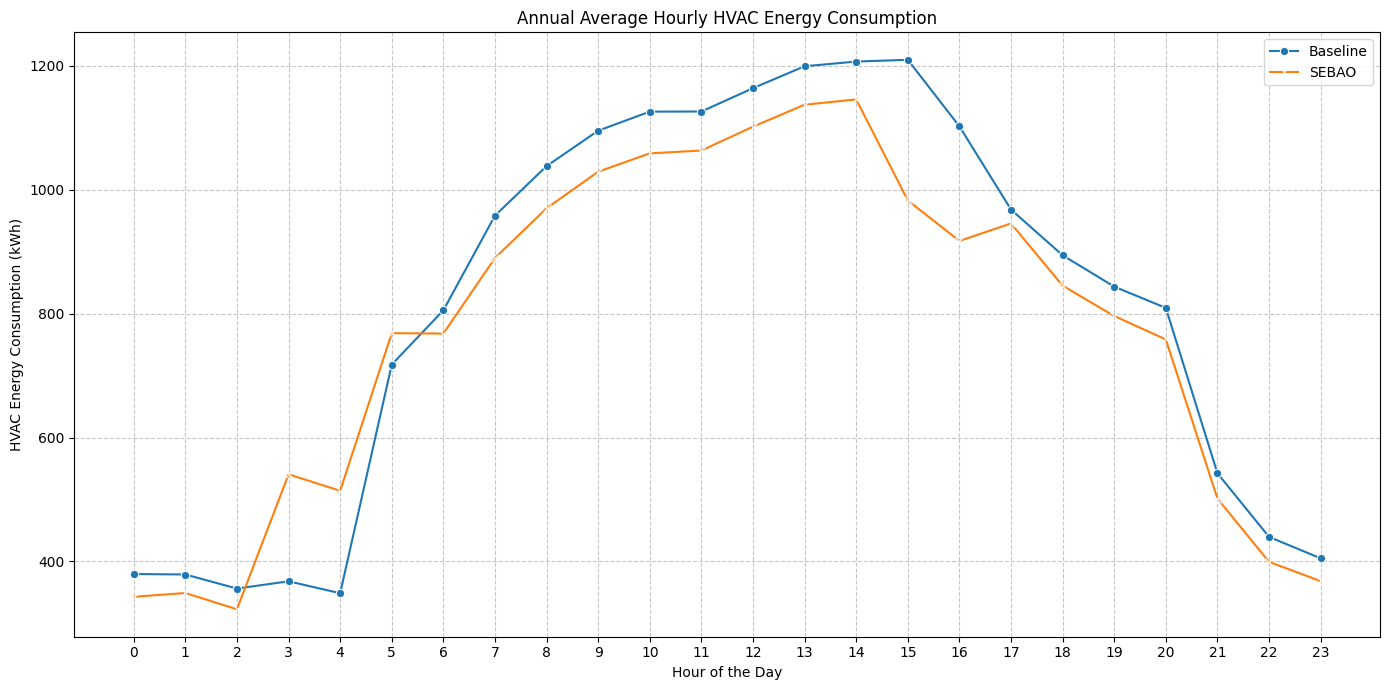

In [ ]:
#  Cellul:32
import matplotlib.pyplot as plt
import seaborn as sns

# Calcul de la consommation énergétique moyenne par heure pour SEBAO-MAS
hourly_energy_sebao = df_sebao.groupby('Hour')['HVAC_Energy_J'].sum() / 3_600_000.0

# Calcul de la consommation énergétique moyenne par heure pour Baseline
hourly_energy_base = df_base.groupby('Hour')['HVAC_Energy_J'].sum() / 3_600_000.0

plt.figure(figsize=(14, 7))
sns.lineplot(x=hourly_energy_base.index, y=hourly_energy_base.values, label='Baseline', marker='o')
sns.lineplot(x=hourly_energy_sebao.index, y=hourly_energy_sebao.values, label='SEBAO', marker='x')

plt.title('Annual Average Hourly HVAC Energy Consumption')
plt.xlabel('Hour of the Day')
plt.ylabel('HVAC Energy Consumption (kWh)')
plt.xticks(range(0, 24)) # Assure que toutes les heures sont affichées sur l'axe des x
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

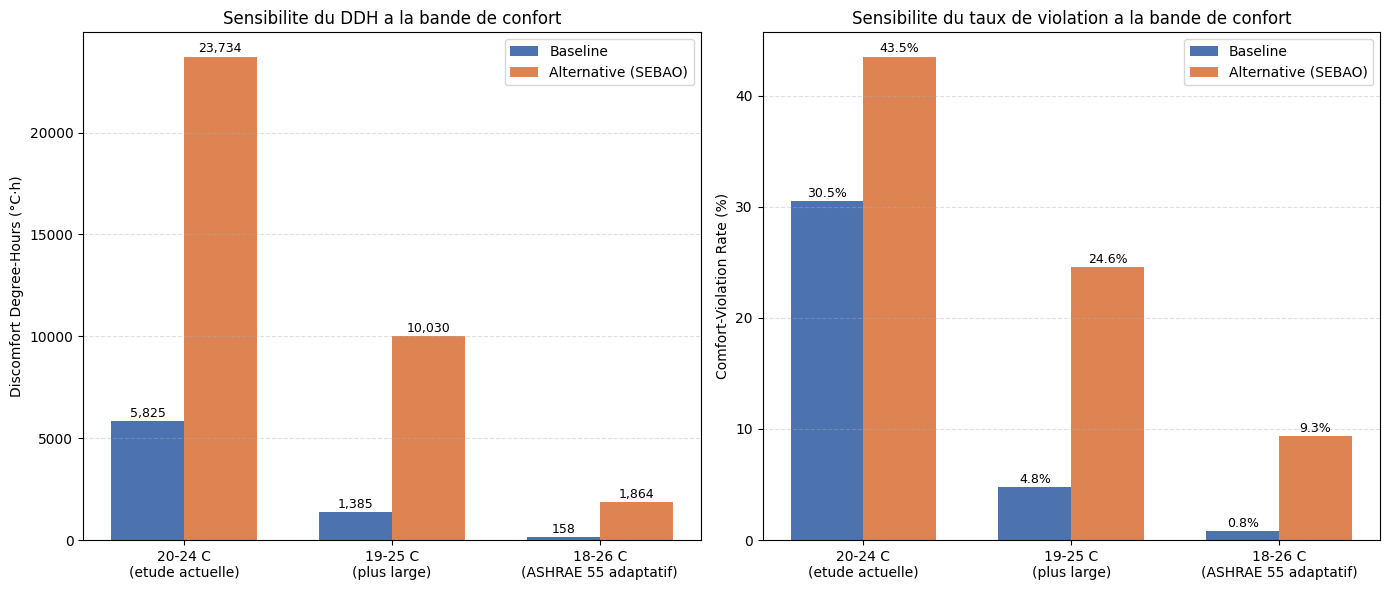

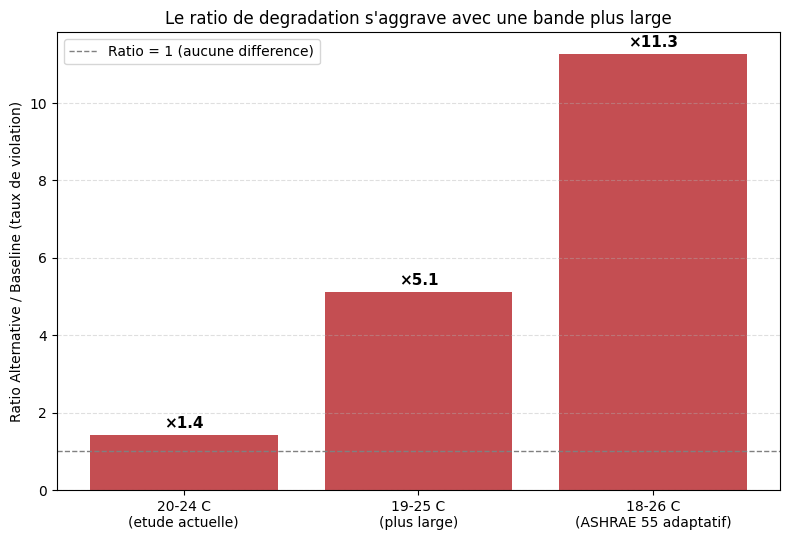

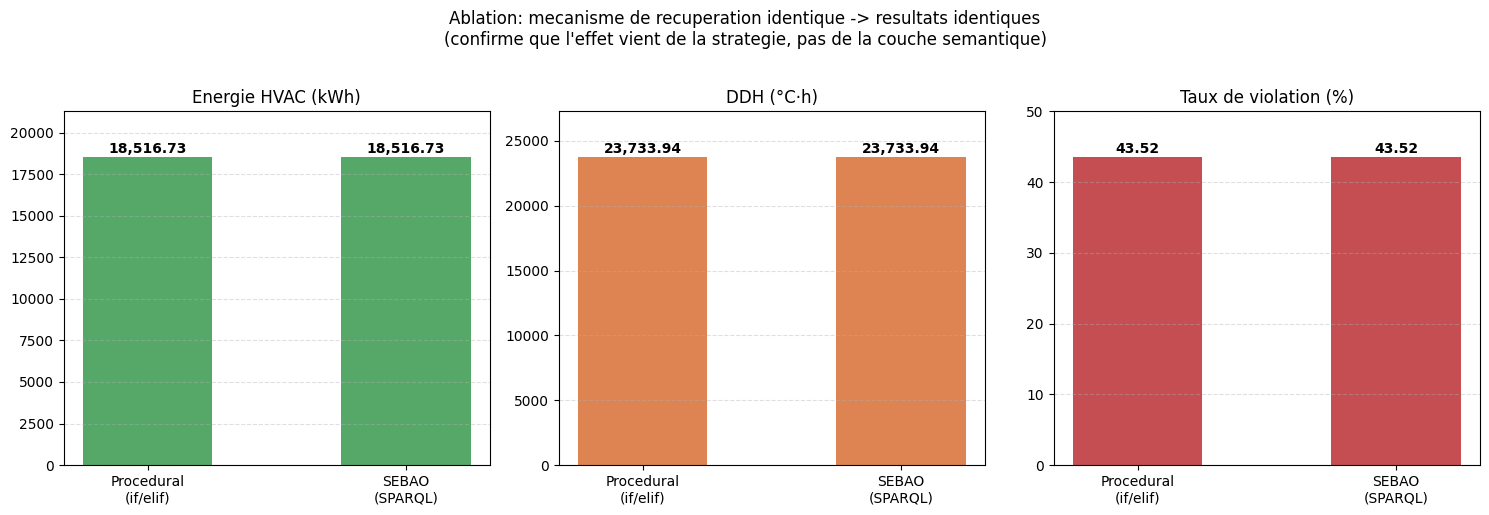

3 figures sauvegardees :
 - fig_w6_sensibilite_bande_confort.png
 - fig_w6_ratio_degradation.png
 - fig_w5_ablation_procedural_vs_sparql.png


In [ ]:
#  Cellul:33
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# GRAPHIQUE 1 — W6 : Sensibilite a la bande de confort
# ============================================================
bandes = ["20-24 C\n(etude actuelle)", "19-25 C\n(plus large)", "18-26 C\n(ASHRAE 55 adaptatif)"]
ddh_base = [5825.27, 1384.97, 157.97]
ddh_sebao = [23733.94, 10029.77, 1863.83]
viol_base = [30.48, 4.80, 0.83]
viol_sebao = [43.52, 24.55, 9.35]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

x = np.arange(len(bandes))
width = 0.35

# --- Sous-graphe gauche : DDH ---
bars1 = ax1.bar(x - width/2, ddh_base, width, label="Baseline", color="#4C72B0")
bars2 = ax1.bar(x + width/2, ddh_sebao, width, label="Alternative (SEBAO)", color="#DD8452")
ax1.set_ylabel("Discomfort Degree-Hours (°C·h)")
ax1.set_title("Sensibilite du DDH a la bande de confort")
ax1.set_xticks(x)
ax1.set_xticklabels(bandes)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.4)
for bars in (bars1, bars2):
    for b in bars:
        h = b.get_height()
        ax1.annotate(f"{h:,.0f}", xy=(b.get_x() + b.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', fontsize=9)

# --- Sous-graphe droit : Taux de violation ---
bars3 = ax2.bar(x - width/2, viol_base, width, label="Baseline", color="#4C72B0")
bars4 = ax2.bar(x + width/2, viol_sebao, width, label="Alternative (SEBAO)", color="#DD8452")
ax2.set_ylabel("Comfort-Violation Rate (%)")
ax2.set_title("Sensibilite du taux de violation a la bande de confort")
ax2.set_xticks(x)
ax2.set_xticklabels(bandes)
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.4)
for bars in (bars3, bars4):
    for b in bars:
        h = b.get_height()
        ax2.annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', fontsize=9)

plt.tight_layout()
plt.savefig("fig_w6_sensibilite_bande_confort.png", dpi=200)
plt.show()

# ============================================================
# GRAPHIQUE 1bis — W6 : Ratio de degradation relative (le point important)
# ============================================================
ratios = [s/b for s, b in zip(viol_sebao, viol_base)]

fig2, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(bandes, ratios, color="#C44E52")
ax.set_ylabel("Ratio Alternative / Baseline (taux de violation)")
ax.set_title("Le ratio de degradation s'aggrave avec une bande plus large")
ax.axhline(1.0, color="grey", linestyle="--", linewidth=1, label="Ratio = 1 (aucune difference)")
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
for b, r in zip(bars, ratios):
    ax.annotate(f"×{r:.1f}", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                xytext=(0, 5), textcoords="offset points", ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig("fig_w6_ratio_degradation.png", dpi=200)
plt.show()

# ============================================================
# GRAPHIQUE 2 — W5 : Ablation procedural vs SPARQL (3 metriques)
# ============================================================
mecanismes = ["Procedural\n(if/elif)", "SEBAO\n(SPARQL)"]
energie = [18516.73, 18516.73]
ddh_ablation = [23733.94, 23733.94]
violation_ablation = [43.52, 43.52]

fig3, axes = plt.subplots(1, 3, figsize=(15, 5))

metriques = [
    ("Energie HVAC (kWh)", energie, "#55A868"),
    ("DDH (°C·h)", ddh_ablation, "#DD8452"),
    ("Taux de violation (%)", violation_ablation, "#C44E52"),
]

for ax, (titre, valeurs, couleur) in zip(axes, metriques):
    bars = ax.bar(mecanismes, valeurs, color=couleur, width=0.5)
    ax.set_title(titre)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    for b, v in zip(bars, valeurs):
        ax.annotate(f"{v:,.2f}", xy=(b.get_x() + b.get_width()/2, v),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', fontsize=10, fontweight='bold')
    # Marge visuelle pour bien montrer l'identite parfaite
    ax.set_ylim(0, max(valeurs) * 1.15)

fig3.suptitle("Ablation: mecanisme de recuperation identique -> resultats identiques\n"
              "(confirme que l'effet vient de la strategie, pas de la couche semantique)",
              fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("fig_w5_ablation_procedural_vs_sparql.png", dpi=200)
plt.show()

print("3 figures sauvegardees :")
print(" - fig_w6_sensibilite_bande_confort.png")
print(" - fig_w6_ratio_degradation.png")
print(" - fig_w5_ablation_procedural_vs_sparql.png")

In [ ]:
#  Cellul:34
#cellul qui permet de sauvgarder les fichies necessair a la phase de prediction
from google.colab import drive
drive.mount('/content/drive')

import os, shutil, json, hashlib, glob
from datetime import datetime

DEST = "/content/drive/MyDrive/SEBAO_outputs/chicago_2026-10-09_v2"  # changez le nom par run
os.makedirs(f"{DEST}/Results", exist_ok=True)

# Définition des fichiers spécifiques
CHEMIN_SANS_ONTOLOGIE = "sebao_energyplus_dataset.csv"
CHEMIN_AVEC_ONTOLOGIE = "Results/SEBAO_Graph_SEBAO-MAS.ttl"

# Indispensables pour la prédiction
fichiers = [
    "Results/contextual_output_Baseline.json",
    "Results/contextual_output_SEBAO-MAS.json",
    "4-prediction_agent.py","Results/SEBAO_Graph_Baseline.ttl",
]

# Utiles pour la reproductibilité (papier / dépôt Zenodo)
fichiers += [
    "baseline_energyplus_dataset.csv",
    CHEMIN_SANS_ONTOLOGIE,
    "2-semantic_agent.py",
    "3-contextual_agent.py",
    "sebao.ttl",
    "Results/shacl_report_Baseline.txt",
    "Results/shacl_report_SEBAO-MAS.txt",
    CHEMIN_AVEC_ONTOLOGIE,  # Inclus explicitement ici
]

fichiers += glob.glob("Results/*.jsonld")

# Sauvegarder d'autres graphes Turtle si nécessaire
SAUVER_AUTRES_TTL = False
if SAUVER_AUTRES_TTL:
    fichiers += glob.glob("Results/SEBAO_Graph_*.ttl")

# Dédoublonnage en conservant l'ordre
fichiers = list(dict.fromkeys(fichiers))

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for bloc in iter(lambda: f.read(1 << 20), b""):
            h.update(bloc)
    return h.hexdigest()

manifest = {"date": datetime.now().isoformat(), "fichiers": {}}
for f in fichiers:
    if not os.path.exists(f):
        print("ABSENT   :", f)
        continue
    cible = f"{DEST}/{f}"
    os.makedirs(os.path.dirname(cible), exist_ok=True)
    shutil.copy2(f, cible)
    assert os.path.getsize(f) == os.path.getsize(cible), f"copie incomplète : {f}"
    manifest["fichiers"][f] = {"octets": os.path.getsize(f), "sha256": sha256(f)}
    print("COPIE OK:", f, f"({os.path.getsize(f)/1e6:.1f} Mo)")

# Nombre d'enregistrements, pour contrôler après rechargement
for lab in ("Baseline", "SEBAO-MAS"):
    p = f"Results/contextual_output_{lab}.json"
    if os.path.exists(p):
        with open(p, encoding="utf-8") as fh:
            manifest.setdefault("enregistrements", {})[lab] = len(json.load(fh))

with open(f"{DEST}/manifest.json", "w", encoding="utf-8") as fh:
    json.dump(manifest, fh, indent=2)

print("\nSauvegarde terminée ->", DEST)
print("Enregistrements :", manifest.get("enregistrements"))
#COPIE OK pour .ttl

Mounted at /content/drive
COPIE OK: Results/contextual_output_Baseline.json (16.9 Mo)
COPIE OK: Results/contextual_output_SEBAO-MAS.json (16.9 Mo)
ABSENT   : 4-prediction_agent.py
COPIE OK: Results/SEBAO_Graph_Baseline.ttl (123.9 Mo)
COPIE OK: baseline_energyplus_dataset.csv (5.4 Mo)
COPIE OK: sebao_energyplus_dataset.csv (9.1 Mo)
COPIE OK: 2-semantic_agent.py (0.0 Mo)
COPIE OK: 3-contextual_agent.py (0.0 Mo)
COPIE OK: sebao.ttl (0.0 Mo)
COPIE OK: Results/shacl_report_Baseline.txt (0.0 Mo)
COPIE OK: Results/shacl_report_SEBAO-MAS.txt (0.0 Mo)
COPIE OK: Results/SEBAO_Graph_SEBAO-MAS.ttl (124.3 Mo)

Sauvegarde terminée -> /content/drive/MyDrive/SEBAO_outputs/chicago_2026-10-09_v2
Enregistrements : {'Baseline': 52560, 'SEBAO-MAS': 52560}


In [ ]:
#Coorection s'arete a c cellul , etape suivante je doit tester le code de benchmark